In [2]:
import os
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

In [3]:
from pathlib import Path

DATA_DIR = Path("../dataset/Original CT Scans")

class_names = ["NiCT", "nCT", "pCT"]

class_counts = {
    name: len(list((DATA_DIR / name).glob("*.jpg")))
    for name in class_names
}

class_counts

{'NiCT': 5705, 'nCT': 9979, 'pCT': 4001}

In [4]:
image_sizes = []

for name in class_names:
    image_paths = (DATA_DIR / name).glob("*.jpg")

    for image_path in image_paths:
        with Image.open(image_path) as img:
            image_sizes.append(img.size)

pd.Series(image_sizes).value_counts()

(512, 512)      13461
(575, 575)       3450
(1211, 1211)     2469
(574, 574)        305
Name: count, dtype: int64

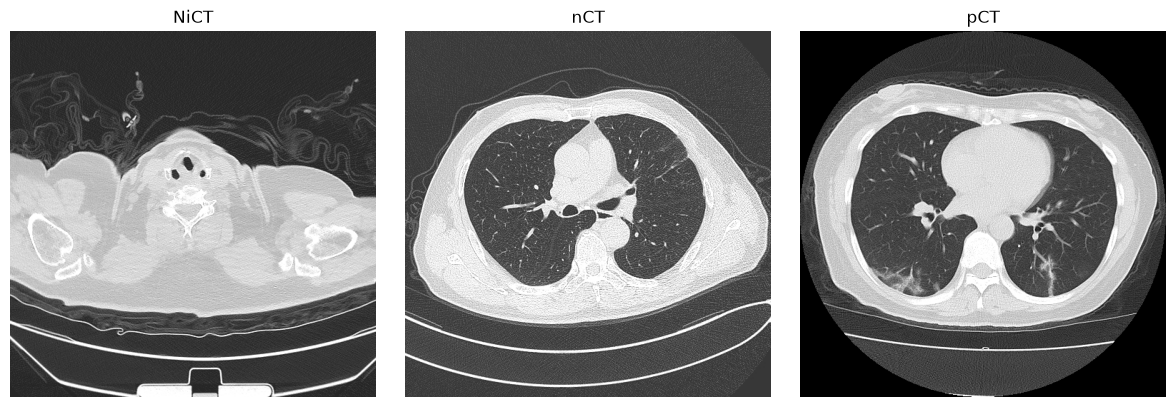

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, name in zip(axes, class_names):
    image_path = next((DATA_DIR / name).glob("*.jpg"))

    with Image.open(image_path) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
class_counts = {
    name: len(list((DATA_DIR / name).glob("*.jpg")))
    for name in class_names
}

class_distribution = pd.Series(class_counts)

class_distribution / class_distribution.sum() * 100

NiCT    28.981458
nCT     50.693421
pCT     20.325121
dtype: float64

## Image Integrity Check

In [7]:
from PIL import Image

invalid_images = []

for class_name in class_names:
    for image_path in (DATA_DIR / class_name).glob("*.jpg"):
        try:
            with Image.open(image_path) as img:
                img.verify()
        except (OSError, ValueError):
            invalid_images.append(image_path)

len(invalid_images)

0

## Image Resolution Analysis

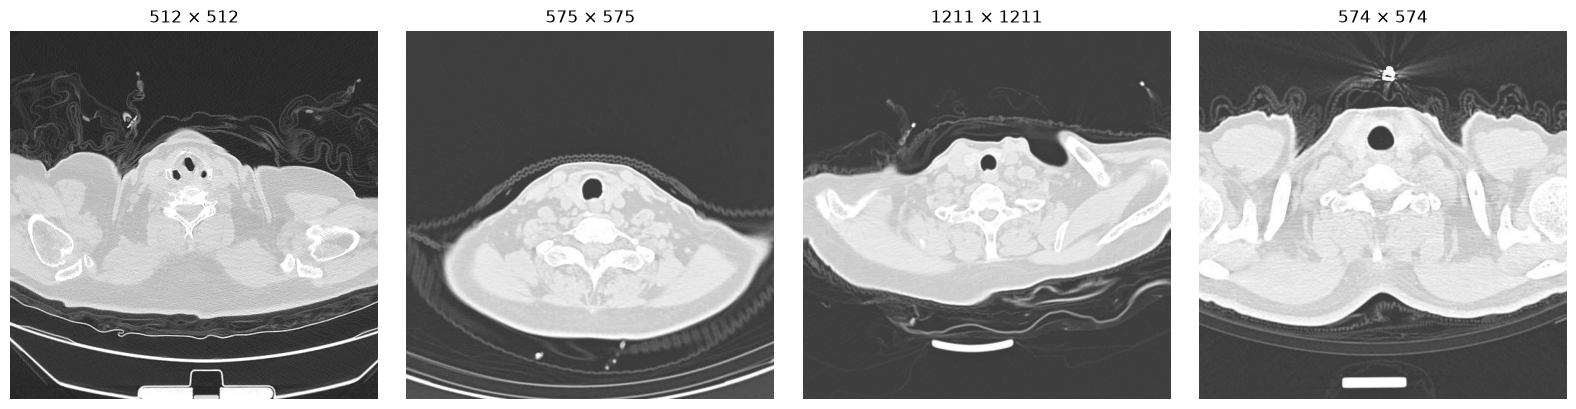

In [9]:
from PIL import Image
import matplotlib.pyplot as plt

sample_sizes = [(512, 512), (575, 575), (1211, 1211), (574, 574)]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, size in zip(axes, sample_sizes):
    image_path = next(
        image_path
        for class_name in class_names
        for image_path in (DATA_DIR / class_name).glob("*.jpg")
        if Image.open(image_path).size == size
    )

    with Image.open(image_path) as img:
        ax.imshow(img, cmap="gray")
        ax.set_title(f"{size[0]} × {size[1]}")
        ax.axis("off")

plt.tight_layout()
plt.show()

## Data Preprocessing

In [14]:
from torchvision import transforms

IMAGE_SIZE = 512

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

In [15]:
from torchvision import datasets

dataset = datasets.ImageFolder(
    root=str(DATA_DIR),
    transform=transform
)

print("Total images:", len(dataset))
print("Classes:", dataset.classes)
print("Class mapping:", dataset.class_to_idx)

Total images: 19685
Classes: ['NiCT', 'nCT', 'pCT']
Class mapping: {'NiCT': 0, 'nCT': 1, 'pCT': 2}


In [17]:
image, label = dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Class name:", dataset.classes[label])

Image shape: torch.Size([3, 512, 512])
Label: 0
Class name: NiCT


In [18]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(dataset))
labels = np.array(dataset.targets)

print("Total samples:", len(indices))
print("Total labels:", len(labels))

Total samples: 19685
Total labels: 19685


In [19]:
train_indices, temp_indices = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

val_indices, test_indices = train_test_split(
    temp_indices,
    test_size=0.50,
    random_state=42,
    stratify=labels[temp_indices]
)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))
print("Test samples:", len(test_indices))

Training samples: 13779
Validation samples: 2953
Test samples: 2953


In [20]:
for name, split_indices in [
    ("Training", train_indices),
    ("Validation", val_indices),
    ("Test", test_indices)
]:
    split_labels = labels[split_indices]
    
    print(f"\n{name}:")
    
    for class_name, class_idx in dataset.class_to_idx.items():
        count = np.sum(split_labels == class_idx)
        percentage = count / len(split_indices) * 100
        
        print(f"{class_name}: {count} ({percentage:.2f}%)")


Training:
NiCT: 3993 (28.98%)
nCT: 6985 (50.69%)
pCT: 2801 (20.33%)

Validation:
NiCT: 856 (28.99%)
nCT: 1497 (50.69%)
pCT: 600 (20.32%)

Test:
NiCT: 856 (28.99%)
nCT: 1497 (50.69%)
pCT: 600 (20.32%)


In [21]:
from torch.utils.data import Subset, DataLoader

train_dataset = Subset(dataset, train_indices.tolist())
val_dataset = Subset(dataset, val_indices.tolist())
test_dataset = Subset(dataset, test_indices.tolist())

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Training: 13779
Validation: 2953
Test: 2953
